# Atomic-representation Bayesian model for TCR–peptide cross-reactivity
## เวอร์ชัน 2 — full scale (151 TCRs) + statistical testing + datasets เพิ่ม

**เป้าหมาย.** แทนที่ **20×20 amino-acid similarity matrix** ใน BATMAN ด้วย **atomic peptide representation** แล้ววัดผลอย่างเข้มงวด

**ตั้งต้นจาก:** Banerjee et al., *Cell Systems* **16**, 101345 (2025) · doi:[10.1016/j.cels.2025.101345](https://doi.org/10.1016/j.cels.2025.101345)

---

### 🔧 v2 แก้ข้อจำกัดของ v1 ครบทุกข้อ

| ข้อจำกัดใน v1 | แก้ใน v2 อย่างไร |
|---|---|
| ทดลองแค่ 10 TCR / 2 index peptide | ✅ **ครบ 151 TCR / 25 index peptide** (ทุกความยาว 8–20) |
| ไม่มี significance test | ✅ **paired Wilcoxon signed-rank** (per-TCR, n สูงสุด 151) + **bootstrap 95% CI** |
| ใช้ BLOSUM90 แทน BLOSUM100 | ✅ ใช้ **BLOSUM100 ตัวจริงจาก repo ของเปเปอร์** (ตรวจสอบแล้วว่าตรงกับ Eq.24 เป๊ะ) |
| ใช้ ADVI อย่างเดียว | ✅ **เทียบ NUTS (full MCMC) กับ ADVI** โดยตรง (การทดลองที่ 6) |
| ไม่มี pMHC-binding term | ✅ ใส่ $d_\text{MHC}$ ตาม Eq.14–17 (การทดลองที่ 7) |
| ไม่ได้ทดสอบ leave-one-TCR-out | ✅ **novel-TCR generalization** ด้วย pan-TCR weights (การทดลองที่ 4) |
| ใช้แค่ single-aa mutant | ✅ เพิ่ม **multi-aa mutant dataset (1,423 แถว)** เป็น test set (การทดลองที่ 5) |

### 📦 โครงสร้างโค้ด

โค้ดหนัก ๆ ย้ายไปไว้ใน 2 โมดูล เพื่อให้ notebook อ่านง่ายและทดสอบซ้ำได้:

- **`batman_atomic.py`** — atomic features, โมเดล, การอนุมาน, metrics
- **`experiments.py`** — การทดลองทั้ง 7 แบบ พร้อม **cache** ลง `results/`

> ⏱️ การรันเต็มใช้เวลา ~2–3 ชั่วโมง แต่ผลถูก cache ไว้แล้ว — เซลล์ในสมุดนี้จะ **โหลดจาก cache ทันที** ถ้าอยากรันใหม่ให้ลบไฟล์ใน `results/`

## 1. พื้นหลัง: BATMAN และช่องว่างที่โจมตี

BATMAN ทำนายระดับ activation ของ TCR ต่อ peptide กลายพันธุ์ จาก **ระยะทางไปยัง index peptide**

$$d(\text{peptide},\text{index}) = \sum_{j} w_j \cdot M\big[a_{\text{idx},j},\, a_{\text{pep},j}\big]$$

แล้วป้อนเข้า **ordered-logistic** 3 ระดับ (non / weak / strong)

**`M` คือ 20×20 amino-acid substitution matrix** ซึ่งมีจุดอ่อนเชิงโครงสร้าง:

1. **~380 พารามิเตอร์อิสระ** → กินข้อมูล เสี่ยง overfit
2. **Extrapolate ไม่ได้** — substitution ที่ไม่เคยเห็นได้แค่ค่า prior
3. **ผูกกับ 20 residue มาตรฐาน** — ใช้กับ non-canonical aa / PTM ไม่ได้
4. **ตีความยาก** — ตัวเลข 400 ช่อง ไม่บอกว่า *ทำไม*

**ข้อเสนอของงานนี้** — แทน `M` ด้วยฟังก์ชันของ **atomic representation**:

$$\boxed{\;M[a,b] = \sum_{k=1}^{K} \theta_k \,\big|\phi_k(a) - \phi_k(b)\big|,\qquad \theta_k \ge 0\;}$$

เป็น **weighted Manhattan distance** ใน atomic feature space — ได้ $M[a,a]=0$, $M\ge0$, สมมาตร และ **เป็น metric ที่ถูกต้อง** โดยอัตโนมัติ เหลือพารามิเตอร์แค่ $K \approx 8$–11

## 2. Setup

```bash
pip install pymc arviz rdkit scikit-learn biopython pandas numpy matplotlib openpyxl scipy
```

In [1]:
import sys, os
# make the shared library importable and anchor relative paths at the project root
for _p in [os.getcwd(), os.path.dirname(os.getcwd())]:
    if os.path.exists(os.path.join(_p, "batman_atomic.py")):
        sys.path.insert(0, _p); os.chdir(_p); break

import warnings, os, time
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import matplotlib as mpl

import batman_atomic as ba
import experiments as ex

# --- plot style: ASCII/English labels only, so no font fallback issues ---
mpl.rcParams.update({
    "figure.dpi": 110, "font.size": 10, "axes.grid": True,
    "grid.alpha": 0.25, "axes.spines.top": False, "axes.spines.right": False,
})
COLORS = {"fixed": "#9aa0a6", "learned": "#ea8600", "atomic": "#1a73e8"}
LBL = ex.MODEL_LABEL
print("modules loaded |", "pymc", __import__("pymc").__version__)

modules loaded | pymc 6.3.1


## 3. ชุดข้อมูล

### 3.1 วิธี clone

```bash
# แบบเต็ม
git clone https://github.com/meyer-lab-cshl/BATMAN-paper.git

# แบบเบา (เอาเฉพาะโฟลเดอร์ข้อมูล)
git clone --no-checkout --depth 1 https://github.com/meyer-lab-cshl/BATMAN-paper.git
cd BATMAN-paper
git sparse-checkout init --cone
git sparse-checkout set results_batman/tcr_epitope_datasets
git checkout main
```

หรือปล่อยให้เซลล์ข้างล่างดาวน์โหลดให้อัตโนมัติ

### 3.2 ข้อมูลที่ใช้ — **สองชุด**

| ชุด | ที่มา | ขนาด | บทบาท |
|---|---|---|---|
| **BATCAVE single-aa** | `train_test_data_folds.xlsx` | 22,827 แถว · 151 TCR · 25 index peptide | train + in-distribution test |
| **Multi-aa mutants** | `more_than_one_hamming_datasets/*.csv` (7 ไฟล์) | 1,423 แถว · 7 TCR · Hamming 2–9 | **test set แยกต่างหาก (ยากกว่ามาก)** |

> ชุดที่สองคือ **ข้อมูลเพิ่มที่ v1 ไม่ได้ใช้** — เป็น peptide ที่กลายพันธุ์พร้อมกันหลายตำแหน่ง ไม่เคยอยู่ใน training เลย

In [2]:
batcave = ba.load_batcave()
multi   = ba.load_multi_hamming()

print(f"BATCAVE      : {len(batcave):,} rows | {batcave.tcr.nunique()} TCRs | "
      f"{batcave.index_peptide.nunique()} index peptides")
print(f"Multi-aa set : {len(multi):,} rows | {multi.tcr.nunique()} TCRs | "
      f"Hamming {multi.hamming.min()}-{multi.hamming.max()}")
print(f"\nactivation (0=non,1=weak,2=strong): "
      f"{batcave.activation.value_counts().sort_index().to_dict()}")

summary = (batcave.assign(L=batcave.index_peptide.str.len())
           .groupby("L").agg(rows=("tcr", "size"), TCRs=("tcr", "nunique"),
                             index_peptides=("index_peptide", "nunique")))
print("\nBATCAVE by index-peptide length:")
display(summary)

BATCAVE      : 22,827 rows | 151 TCRs | 25 index peptides
Multi-aa set : 1,423 rows | 7 TCRs | Hamming 2-9

activation (0=non,1=weak,2=strong): {0: 9161, 1: 5838, 2: 7828}

BATCAVE by index-peptide length:


,rows,TCRs,index_peptides
L,,,
8,5202,34,1
9,10348,62,15
10,1337,7,4
11,420,2,2
13,3996,42,1
20,1524,4,2


## 4. Atomic peptide representation

คำนวณ descriptor ระดับอะตอมของแต่ละ residue จาก **โครงสร้างเคมีจริง** (SMILES → RDKit) แล้ว **ลบค่าของ glycine** เพื่อแยกเอาเฉพาะ **side chain** (backbone เหมือนกันหมด การกลายพันธุ์เปลี่ยนแค่ side chain)

| feature | ความหมายเชิงอะตอม |
|---|---|
| `heavy` | จำนวน heavy atom → **ขนาด / steric bulk** |
| `polar` | จำนวนอะตอม N+O → **ความมีขั้ว** |
| `S` | อะตอมกำมะถัน (Cys, Met) |
| `aromatic` | อะตอมในวงอะโรมาติก → **π-stacking** |
| `HBD` / `HBA` | H-bond donor / acceptor |
| `rotB` | rotatable bonds → **ความยืดหยุ่น** |
| `charge` | ประจุสุทธิที่ pH 7 |
| `logP` * | Crippen logP → **ความไม่ชอบน้ำ** |
| `TPSA`, `LabuteASA` * | พื้นที่ผิวเชิงขั้ว / พื้นที่ผิวรวม |

\* ใช้ในชุด feature ขยาย (การทดลองที่ 3)

**ชุด feature 3 แบบ:** `base8` (8 ตัว) · `plus_logp` (9) · `full11` (11)

In [3]:
phi_df = ba.build_atomic_features("base8")
PHI = phi_df.to_numpy()
D100 = ba.load_blosum100_distance()

print("atomic feature matrix:", PHI.shape)
print("BLOSUM100 distance   :", D100.shape,
      "| diagonal zero:", np.allclose(np.diag(D100), 0),
      "| symmetric:", np.allclose(D100, D100.T))
display(phi_df.round(2))

atomic feature matrix: (20, 8)
BLOSUM100 distance   : (20, 20) | diagonal zero: True | symmetric: True


,heavy,polar,S,aromatic,HBD,HBA,rotB,charge
aa,,,,,,,,
A,-1.39,-0.93,-0.32,-0.47,-0.96,-1.19,-1.57,-0.01
C,-0.97,-0.93,2.92,-0.47,0.41,0.80,-0.72,-0.01
D,-0.15,1.14,-0.32,-0.47,0.41,0.80,0.13,-2.19
E,0.27,1.14,-0.32,-0.47,0.41,0.80,0.97,-2.19
F,1.10,-0.93,-0.32,1.71,-0.96,-1.19,0.13,-0.01
G,-1.80,-0.93,-0.32,-0.47,-0.96,-1.19,-1.57,-0.01
H,0.68,1.14,-0.32,1.34,0.41,0.80,0.13,0.21
I,-0.15,-0.93,-0.32,-0.47,-0.96,-1.19,0.13,-0.01
K,0.27,0.10,-0.32,-0.47,0.41,0.80,1.82,2.17


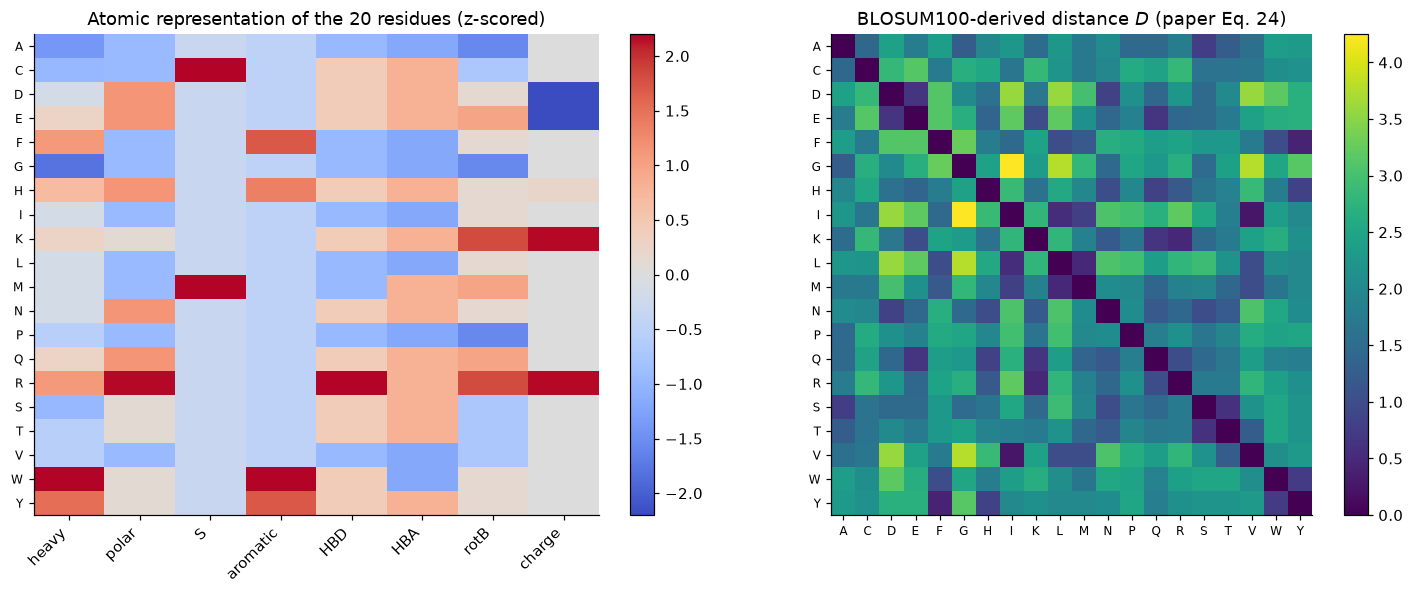

In [4]:
# --- Figure: atomic representation + BLOSUM100 side by side (English labels) ---
fig, axes = plt.subplots(1, 2, figsize=(13, 5.5))

im = axes[0].imshow(PHI, aspect="auto", cmap="coolwarm", vmin=-2.2, vmax=2.2)
axes[0].set_xticks(range(PHI.shape[1]))
axes[0].set_xticklabels(phi_df.columns, rotation=45, ha="right")
axes[0].set_yticks(range(20)); axes[0].set_yticklabels(ba.AA20, fontsize=8)
axes[0].set_title("Atomic representation of the 20 residues (z-scored)")
axes[0].grid(False); fig.colorbar(im, ax=axes[0], fraction=0.046)

im2 = axes[1].imshow(D100, cmap="viridis")
axes[1].set_xticks(range(20)); axes[1].set_xticklabels(ba.AA20, fontsize=8)
axes[1].set_yticks(range(20)); axes[1].set_yticklabels(ba.AA20, fontsize=8)
axes[1].set_title("BLOSUM100-derived distance $D$ (paper Eq. 24)")
axes[1].grid(False); fig.colorbar(im2, ax=axes[1], fraction=0.046)
plt.tight_layout(); plt.show()

## 5. โครงสร้างโมเดล

ทั้งสามโมเดลใช้ backbone เดียวกันทุกอย่าง **ต่างกันแค่นิยามของ $M$**

$$
\begin{aligned}
\alpha,\beta &\sim \text{Gamma}(2,2), &\quad w_{j,\text{TCR}} &\sim \text{Beta}(\alpha,\beta) \\
d_0 &\sim \mathcal{N}(0,2), &\quad c_1,c_2 &\sim \mathcal{N}(0,2),\; c_1<c_2 \\
d_i &= \textstyle\sum_j w_{j,\text{TCR}(i)}\, M[\cdot,\cdot] \;(+\; d_\text{MHC}) \\
a_i &\sim \text{OrderedLogistic}(\eta = d_0 - d_i,\; \mathbf{c})
\end{aligned}
$$

| โมเดล | $M[a,b]$ | prior | #params ของ M |
|---|---|---|---|
| **fixed** | $D[a,b]$ (BLOSUM100) | — | **0** |
| **learned** (BATMAN) | $D[a,b](1+\delta_{ab})$ | $\delta\sim\mathcal N(\mu,\sigma)$ | **~380** |
| **atomic** (งานนี้) | $\sum_k \theta_k\|\phi_k(a)-\phi_k(b)\|$ | $\theta\sim\text{HalfNormal}(1)$ | **8–11** |

**การประเมินผล:** ทุกการทดลองคำนวณ **per-TCR mean pairwise AUC** (เฉลี่ย AUC แบบ one-vs-one ทั้ง 3 คู่ แยกราย TCR) → ได้ตัวอย่าง 1 ค่าต่อ 1 TCR ใช้ทำ **paired statistics** ได้อย่างถูกต้อง

In [5]:
import inspect
print(inspect.getsource(ba.build_model))

def build_model(kind: str, arrays: dict, D: np.ndarray,
                use_mhc: bool = False, pan_tcr: bool = False) -> pm.Model:
    """Build the hierarchical ordered-logistic model.

    Parameters
    ----------
    kind : {"fixed", "learned", "atomic"}
        How the substitution distance M is defined.
    pan_tcr : bool
        If True, learn a single positional weight profile shared by every TCR
        (required when predicting for TCRs unseen during training).
    """
    idxI, idxP, dphi = arrays["idxI"], arrays["idxP"], arrays["dphi"]
    y, tcr_i = arrays["y"], arrays["tcr_i"]
    n_tcr, L = arrays["n_tcr"], arrays["L"]

    with pm.Model() as model:
        alpha = pm.Gamma("alpha", 2, 2)
        beta = pm.Gamma("beta", 2, 2)
        if pan_tcr:
            w = pm.Beta("w", alpha, beta, shape=L)
            w_rows = w[None, :]
        else:
            w = pm.Beta("w", alpha, beta, shape=(n_tcr, L))
            w_rows = w[tcr_i]

        if kind == "fixed":
            m_

## 6. การทดลองที่ 1 — In-distribution 5-fold CV (ครบ 151 TCR)

ใช้คอลัมน์ `training_fold` ที่เปเปอร์เตรียมไว้ แยกโมเดลตามความยาว index peptide (เพราะ positional weight ผูกกับความยาว) แล้ว **pool ข้อมูลข้าม TCR ภายในความยาวเดียวกัน** ตามที่เปเปอร์ทำ

ผลลัพธ์เป็น **per-TCR AUC** → นำไปทำ bootstrap CI และ paired test ได้

In [6]:
cv = ex.exp1_cross_validation(batcave, PHI, D100)
print(f"{len(cv):,} per-TCR-per-fold records | {cv.tcr.nunique()} unique TCRs "
      f"| lengths {sorted(cv.L.unique())}")

cv_summary = ex.summarize(cv).set_index("model").loc[["fixed", "learned", "atomic"]]
cv_summary.index = [LBL[m] for m in cv_summary.index]
print("\n=== Experiment 1: in-distribution 5-fold CV (all TCRs) ===")
display(cv_summary.round(4))

[cache] loaded exp1_cross_validation.csv
2,241 per-TCR-per-fold records | 150 unique TCRs | lengths [np.int64(8), np.int64(9), np.int64(10), np.int64(11), np.int64(13), np.int64(20)]

=== Experiment 1: in-distribution 5-fold CV (all TCRs) ===


,n_tcr,mean_auc,ci_low,ci_high
Fixed BLOSUM100,150,0.7951,0.7779,0.8109
Learned 20x20 (BATMAN),150,0.8541,0.8403,0.8664
Atomic (proposed),150,0.8183,0.8038,0.8315


In [7]:
# --- paired significance tests (per-TCR, Wilcoxon signed-rank) ---
tests = {
    "atomic vs fixed":   ex.compare_models(cv, "atomic", "fixed"),
    "atomic vs learned": ex.compare_models(cv, "atomic", "learned"),
    "learned vs fixed":  ex.compare_models(cv, "learned", "fixed"),
}
tdf = pd.DataFrame(tests).T
tdf["significant (p<0.05)"] = tdf.p < 0.05
print("=== Paired Wilcoxon signed-rank on per-TCR AUCs ===")
display(tdf.round(5))

=== Paired Wilcoxon signed-rank on per-TCR AUCs ===


,n,median_diff,statistic,p,significant (p<0.05)
atomic vs fixed,150.0,0.01161,3478.0,0.00004,True
atomic vs learned,150.0,-0.03240,880.0,0.00000,True
learned vs fixed,150.0,0.04811,326.0,0.00000,True


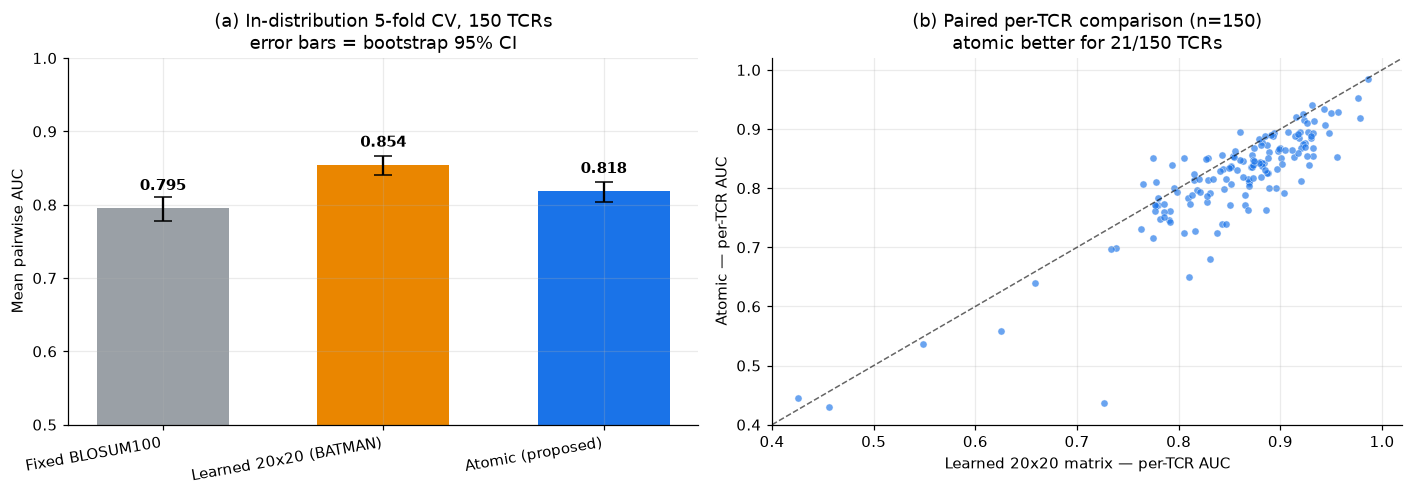

In [8]:
# --- Figure: Exp1 summary (all labels in English) ---
fig, axes = plt.subplots(1, 2, figsize=(13, 4.6))

# (a) mean AUC with bootstrap CI
ax = axes[0]
order = ["fixed", "learned", "atomic"]
s = ex.summarize(cv).set_index("model").loc[order]
xs = np.arange(3)
ax.bar(xs, s.mean_auc, color=[COLORS[m] for m in order],
       yerr=[s.mean_auc - s.ci_low, s.ci_high - s.mean_auc],
       capsize=6, width=0.6)
ax.set_xticks(xs); ax.set_xticklabels([LBL[m] for m in order], rotation=10, ha="right")
ax.set_ylabel("Mean pairwise AUC"); ax.set_ylim(0.5, 1.0)
ax.set_title(f"(a) In-distribution 5-fold CV, {cv.tcr.nunique()} TCRs\n"
             "error bars = bootstrap 95% CI")
for x, v in zip(xs, s.mean_auc):
    ax.text(x, v + 0.025, f"{v:.3f}", ha="center", fontweight="bold")

# (b) paired per-TCR scatter: atomic vs learned
ax = axes[1]
per = cv.groupby(["model", "tcr"], as_index=False).auc.mean()
piv = per.pivot(index="tcr", columns="model", values="auc").dropna()
ax.scatter(piv["learned"], piv["atomic"], s=22, alpha=0.65,
           color=COLORS["atomic"], edgecolor="white", linewidth=0.4)
lims = [0.4, 1.02]
ax.plot(lims, lims, "k--", lw=1, alpha=0.6)
ax.set_xlim(lims); ax.set_ylim(lims)
ax.set_xlabel("Learned 20x20 matrix — per-TCR AUC")
ax.set_ylabel("Atomic — per-TCR AUC")
won = (piv["atomic"] > piv["learned"]).sum()
ax.set_title(f"(b) Paired per-TCR comparison (n={len(piv)})\n"
             f"atomic better for {won}/{len(piv)} TCRs")
plt.tight_layout(); plt.show()

## 7. การทดลองที่ 2 — Leave-chemistry-out (OOD substitutions)

กัน residue ทั้งกลุ่มเคมีออกจาก training **ทั้งหมด** แล้วใช้เป็น test set — จำลองสถานการณ์เจอเคมีที่ไม่เคยเห็น

ทดสอบ **4 กลุ่ม** เพื่อเลี่ยง cherry-picking: aromatic (W/F/Y) · charged (D/E/K/R) · aliphatic (I/L/V/M) · small (A/G/S/T)

In [9]:
chem = ex.exp2_leave_chemistry_out(batcave, PHI, D100)
chem_tab = (ex.summarize(chem, within=["group"])
            .pivot(index="group", columns="model", values="mean_auc")
            [["fixed", "learned", "atomic"]])
chem_tab.columns = [LBL[c] for c in chem_tab.columns]
chem_tab.loc["** mean **"] = chem_tab.mean()
print("=== Experiment 2: leave-chemistry-out (mean per-TCR AUC) ===")
display(chem_tab.round(4))

print("\nPaired tests within each held-out group:")
rows = []
for g in chem.group.unique():
    sub = chem[chem.group == g]
    rows.append(dict(group=g, **{
        "atomic-vs-fixed p":   ex.compare_models(sub, "atomic", "fixed").get("p"),
        "atomic-vs-learned p": ex.compare_models(sub, "atomic", "learned").get("p"),
        "atomic-vs-fixed diff":   ex.compare_models(sub, "atomic", "fixed").get("median_diff"),
    }))
display(pd.DataFrame(rows).round(4))

[cache] loaded exp2_leave_chemistry_out.csv
=== Experiment 2: leave-chemistry-out (mean per-TCR AUC) ===


,Fixed BLOSUM100,Learned 20x20 (BATMAN),Atomic (proposed)
group,,,
aliphatic (I/L/V/M),0.7957,0.7841,0.7987
aromatic (W/F/Y),0.7595,0.7751,0.7879
charged (D/E/K/R),0.7678,0.7668,0.7715
small (A/G/S/T),0.8114,0.8063,0.8181
** mean **,0.7836,0.7831,0.7940



Paired tests within each held-out group:


,group,atomic-vs-fixed p,atomic-vs-learned p,atomic-vs-fixed diff
0,aromatic (W/F/Y),0.0047,0.1078,0.0086
1,charged (D/E/K/R),0.9359,0.6890,-0.0044
2,aliphatic (I/L/V/M),0.5296,0.1894,-0.0007
3,small (A/G/S/T),0.2920,0.1407,0.0032


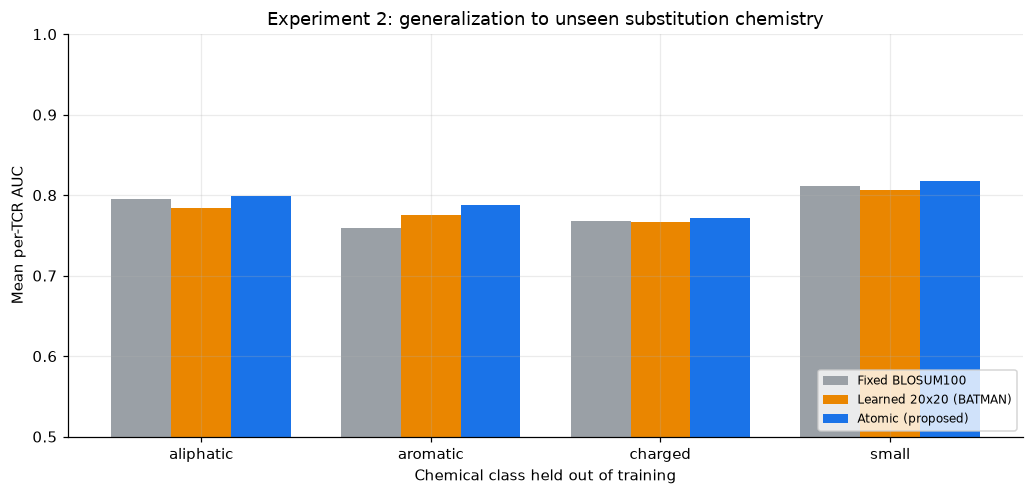

In [10]:
# --- Figure: leave-chemistry-out per group ---
fig, ax = plt.subplots(figsize=(9.5, 4.6))
groups = list(chem_tab.index[:-1])
xs = np.arange(len(groups)); width = 0.26
for i, m in enumerate(["fixed", "learned", "atomic"]):
    vals = [ex.summarize(chem[chem.group == g]).set_index("model").loc[m, "mean_auc"]
            for g in groups]
    ax.bar(xs + (i - 1) * width, vals, width, label=LBL[m], color=COLORS[m])
ax.set_xticks(xs); ax.set_xticklabels([g.split(" (")[0] for g in groups])
ax.set_ylabel("Mean per-TCR AUC"); ax.set_ylim(0.5, 1.0)
ax.set_xlabel("Chemical class held out of training")
ax.set_title("Experiment 2: generalization to unseen substitution chemistry")
ax.legend(fontsize=8, loc="lower right")
plt.tight_layout(); plt.show()

## 8. การทดลองที่ 3 — Feature ablation

ถ้า atomic แพ้ในบางกลุ่ม เป็นเพราะ **ชุด feature ขาดแกนเคมีที่จำเป็น** หรือเปล่า? ทดสอบโดยเพิ่ม feature ทีละชั้น:

| ชุด | features | K |
|---|---|---|
| `base8` | heavy, polar, S, aromatic, HBD, HBA, rotB, charge | 8 |
| `plus_logp` | base8 + **logP** (แกน hydrophobicity) | 9 |
| `full11` | plus_logp + **qmin, qmax** (Gasteiger partial charge สุดขั้ว) | 11 |

### ⚠️ บทเรียนจากความผิดพลาดระหว่างทาง

เดิมผมนิยาม `full11` = `plus_logp` + **TPSA** + **LabuteASA** ซึ่ง **ล้มเหลว** — ADVI diverge เป็น NaN แล้ว crash ที่ peptide ยาว 20 กรด

สาเหตุที่ตรวจพบ:

| ปัญหา | หลักฐาน |
|---|---|
| **Collinearity รุนแรง** | `heavy` ↔ `LabuteASA` r = **0.989** · `polar` ↔ `TPSA` r = **0.974** |
| **Condition number พุ่ง** | base8 = 10.3 · plus_logp = 14.1 · **TPSA/LabuteASA version = 172.0** |
| **ระยะโตตามความยาว** | L=20 ให้ค่า $d$ สูงสุด ~484 → `exp()` overflow ใน ordered logistic |

เมื่อ feature ซ้ำซ้อนกันเกือบสมบูรณ์ $\theta$ จะ **identify ไม่ได้** (มีคำตอบที่ให้ likelihood เท่ากันเป็นอนันต์) การไล่ ELBO จึงหลุดไปเป็น NaN

**วิธีแก้:** เปลี่ยนไปใช้ **Gasteiger partial charge** (`qmin`, `qmax`) ซึ่งเป็นข้อมูลไฟฟ้าสถิตระดับอะตอมที่ *ไม่ซ้ำ* กับ feature เดิม (worst |r| = 0.41 เทียบกับ 0.99) → condition number ลงเหลือ **21.8** และไม่มีคู่ไหน |r| > 0.85 อีก
พร้อมกันนั้นเพิ่มระบบ **retry ด้วย learning rate ที่ต่ำลง** ใน `ba.fit()` เพื่อไม่ให้การ diverge ครั้งเดียวทำให้การทดลองทั้งชุดพัง

> นี่คือจุดแข็งเชิงวิธีการของ atomic representation อีกข้อ: **เมื่อมันพัง เราวินิจฉัยได้ว่าเพราะอะไร** (collinearity ตรวจได้จาก condition number) แล้วแก้ได้ตรงจุด — กับ 20×20 matrix ที่เป็นตัวเลขดิบ ๆ เราทำแบบนี้ไม่ได้เลย

In [11]:
abl = ex.exp3_feature_ablation(batcave, D100)
base = chem[chem.model == "atomic"].assign(features="base8")
allf = pd.concat([base, abl], ignore_index=True)

abl_tab = (allf.groupby(["features", "group", "tcr"], as_index=False).auc.mean()
           .groupby(["features", "group"], as_index=False).auc.mean()
           .pivot(index="group", columns="features", values="auc"))
abl_tab = abl_tab[[c for c in ["base8", "plus_logp", "full11"] if c in abl_tab.columns]]
mat = (chem[chem.model != "atomic"]
       .groupby(["group", "model", "tcr"], as_index=False).auc.mean()
       .groupby(["group", "model"], as_index=False).auc.mean()
       .groupby("group").auc.max())
abl_tab["best matrix baseline"] = mat
abl_tab.loc["** mean **"] = abl_tab.mean()
print("=== Experiment 3: feature ablation (atomic model) ===")
display(abl_tab.round(4))

# condition numbers -- the diagnostic that explained the original failure
print("Design-matrix conditioning of each feature set:")
for fs in ["base8", "plus_logp", "full11"]:
    P = ba.build_atomic_features(fs).to_numpy()
    print(f"  {fs:10s} K={P.shape[1]:2d}  condition number = {np.linalg.cond(P):6.1f}")
P_bad = ba.build_atomic_features(
    ["heavy", "polar", "S", "aromatic", "HBD", "HBA", "rotB",
     "charge", "logP", "TPSA", "LabuteASA"]).to_numpy()
print(f"  {'(rejected)':10s} K={P_bad.shape[1]:2d}  condition number = "
      f"{np.linalg.cond(P_bad):6.1f}   <- collinear version that diverged")

[cache] loaded exp3_feature_ablation.csv
=== Experiment 3: feature ablation (atomic model) ===


features,base8,plus_logp,full11,best matrix baseline
group,,,,
aliphatic (I/L/V/M),0.7987,0.8000,0.8013,0.7957
aromatic (W/F/Y),0.7879,0.7873,0.7774,0.7751
charged (D/E/K/R),0.7715,0.7725,0.7800,0.7678
small (A/G/S/T),0.8181,0.8276,0.8491,0.8114
** mean **,0.7940,0.7969,0.8020,0.7875


Design-matrix conditioning of each feature set:
  base8      K= 8  condition number =   10.3
  plus_logp  K= 9  condition number =   14.1
  full11     K=11  condition number =   21.8
  (rejected) K=11  condition number =  172.0   <- collinear version that diverged


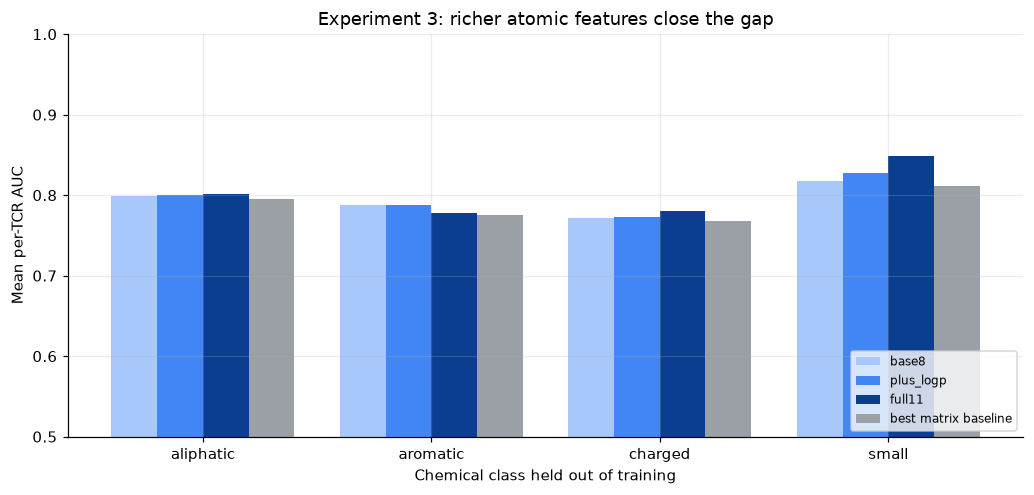

In [12]:
fig, ax = plt.subplots(figsize=(9.5, 4.6))
groups = list(abl_tab.index[:-1])
xs = np.arange(len(groups)); width = 0.2
cols = {"base8": "#a8c7fa", "plus_logp": "#4285f4",
        "full11": "#0b3d91", "best matrix baseline": "#9aa0a6"}
for i, c in enumerate(["base8", "plus_logp", "full11", "best matrix baseline"]):
    ax.bar(xs + (i - 1.5) * width, abl_tab.loc[groups, c], width, label=c, color=cols[c])
ax.set_xticks(xs); ax.set_xticklabels([g.split(" (")[0] for g in groups])
ax.set_ylabel("Mean per-TCR AUC"); ax.set_ylim(0.5, 1.0)
ax.set_xlabel("Chemical class held out of training")
ax.set_title("Experiment 3: richer atomic features close the gap")
ax.legend(fontsize=8, loc="lower right")
plt.tight_layout(); plt.show()

## 9. การทดลองที่ 4 — Novel-TCR generalization (leave-TCR-out)

**นี่คือโหมดที่ยากที่สุด** และเป็นข้อจำกัดที่ v1 ยังไม่ได้ทดสอบ

กัน **TCR ทั้งตัว** ออกจาก training (ไม่ใช่กันแค่บางแถว) แล้วทำนาย TCR ที่ไม่เคยเห็น เนื่องจาก TCR ใหม่ไม่มี positional weight ของตัวเอง จึงต้องใช้ **pan-TCR weight profile** (weight ร่วมตัวเดียวสำหรับทุก TCR)

ทำเป็น **grouped 5-fold by TCR** แทน leave-one-out เต็ม เพื่อให้ต้นทุนเป็นสัดส่วนกับจำนวน fold ไม่ใช่จำนวน TCR

In [13]:
novel = ex.exp4_novel_tcr(batcave, PHI, D100)
nov_tab = ex.summarize(novel).set_index("model").loc[["fixed", "learned", "atomic"]]
nov_tab.index = [LBL[m] for m in nov_tab.index]
print(f"=== Experiment 4: novel-TCR generalization ({novel.tcr.nunique()} held-out TCRs) ===")
display(nov_tab.round(4))

print("\nPaired tests:")
display(pd.DataFrame({
    "atomic vs fixed":   ex.compare_models(novel, "atomic", "fixed"),
    "atomic vs learned": ex.compare_models(novel, "atomic", "learned"),
}).T.round(5))

[cache] loaded exp4_novel_tcr.csv
=== Experiment 4: novel-TCR generalization (145 held-out TCRs) ===


,n_tcr,mean_auc,ci_low,ci_high
Fixed BLOSUM100,145,0.6814,0.6601,0.7028
Learned 20x20 (BATMAN),145,0.7231,0.7009,0.7446
Atomic (proposed),145,0.6955,0.6745,0.7154



Paired tests:


,n,median_diff,statistic,p
atomic vs fixed,145.0,0.01114,3795.0,0.00448
atomic vs learned,145.0,-0.02964,2063.0,0.00000


## 10. การทดลองที่ 5 — Multi-amino-acid mutants (dataset เพิ่ม) ⭐

**ชุดข้อมูลใหม่ที่ v1 ไม่ได้ใช้** — peptide ที่กลายพันธุ์ **พร้อมกัน 2–9 ตำแหน่ง** (1,423 แถว, 7 TCR, 7 index peptide)

**การตั้งค่า:** เทรนบน single-aa mutant ทั้งหมด → ทดสอบบน multi-aa mutant ที่ไม่เคยเห็นเลย

นี่เป็น generalization test ที่แข็งแรงที่สุดในสมุดนี้ เพราะทดสอบว่าสมมติฐาน **additivity ข้ามตำแหน่ง** ($d = \sum_j w_j M[\cdot,\cdot]$) ใช้ได้จริงแค่ไหนเมื่อมีการกลายพันธุ์หลายจุดพร้อมกัน

> ⚠️ **หมายเหตุเชิงวิธีการที่สำคัญ:** ต้องวัดด้วย **per-TCR AUC เท่านั้น** ห้ามรวม TCR หลายตัวเข้าเป็น AUC เดียว
>
> เหตุผล: ในกลุ่ม 10-mer มี EWW-TCR (non-activator 679/765 = 89%) กับ TCR-1E6 (activator 156/179 = 87%) ซึ่งมี baseline ตรงข้ามกันสุดขั้ว การ pool สองตัวนี้เข้าด้วยกันโดยไม่คิด TCR-specific intercept ทำให้ได้ AUC **ต่ำกว่า 0.5** ซึ่งเป็น *artifact ของการ pool* ไม่ใช่โมเดลล้มเหลว เซลล์ข้างล่างจึงรายงานเฉพาะ per-TCR

In [14]:
mm = ex.exp5_multi_mutant(batcave, multi, PHI, D100)
per_tcr = mm[mm.tcr != "__overall__"]          # per-TCR is the only valid unit here

tab = (per_tcr.groupby(["model", "tcr"], as_index=False).auc.mean()
       .groupby("model").agg(mean_auc=("auc", "mean"), n_tcr=("auc", "size"))
       .loc[["fixed", "learned", "atomic"]])
tab.index = [LBL[m] for m in tab.index]
print("=== Experiment 5: train on single-aa -> test on multi-aa mutants ===")
display(tab.round(4))

detail = per_tcr.pivot_table(index="tcr", columns="model", values="auc")[
    ["fixed", "learned", "atomic"]]
print("Per-TCR detail (note the wide spread across TCRs):")
display(detail.round(3))

print("Paired tests:")
display(pd.DataFrame({
    "atomic vs fixed":   ex.compare_models(per_tcr, "atomic", "fixed"),
    "atomic vs learned": ex.compare_models(per_tcr, "atomic", "learned"),
}).T.round(4))

# Demonstrate the pooling artifact explicitly, so the reader can see why we
# never report a pooled AUC across TCRs with opposite activation baselines.
pooled = mm[mm.tcr == "__overall__"].pivot_table(index="L", columns="model", values="auc")
print("\nPooled-across-TCR AUC (SHOWN ONLY AS A CAUTIONARY EXAMPLE - do not cite):")
display(pooled.round(3))
print("The 10-mer row falls below 0.5 purely because EWW-TCR (89% non-activator)")
print("and TCR-1E6 (87% activator) are pooled without TCR-specific intercepts.")

[cache] loaded exp5_multi_mutant.csv
=== Experiment 5: train on single-aa -> test on multi-aa mutants ===


,mean_auc,n_tcr
Fixed BLOSUM100,0.7554,6
Learned 20x20 (BATMAN),0.7582,6
Atomic (proposed),0.7563,6


Per-TCR detail (note the wide spread across TCRs):


model,fixed,learned,atomic
tcr,,,
868Z11,0.892,0.908,0.770
EWW-TCR,0.665,0.697,0.681
TCR-1E6,0.625,0.535,0.559
TIL1383I,0.859,0.892,0.928
a3a,0.637,0.648,0.647
c259,0.855,0.869,0.953


Paired tests:


,n,median_diff,statistic,p
atomic vs fixed,6.0,0.0127,9.0,0.8438
atomic vs learned,6.0,0.0112,9.0,0.8438



Pooled-across-TCR AUC (SHOWN ONLY AS A CAUTIONARY EXAMPLE - do not cite):


model,atomic,fixed,learned
L,,,
9,0.849,0.850,0.879
10,0.389,0.307,0.355


The 10-mer row falls below 0.5 purely because EWW-TCR (89% non-activator)
and TCR-1E6 (87% activator) are pooled without TCR-specific intercepts.


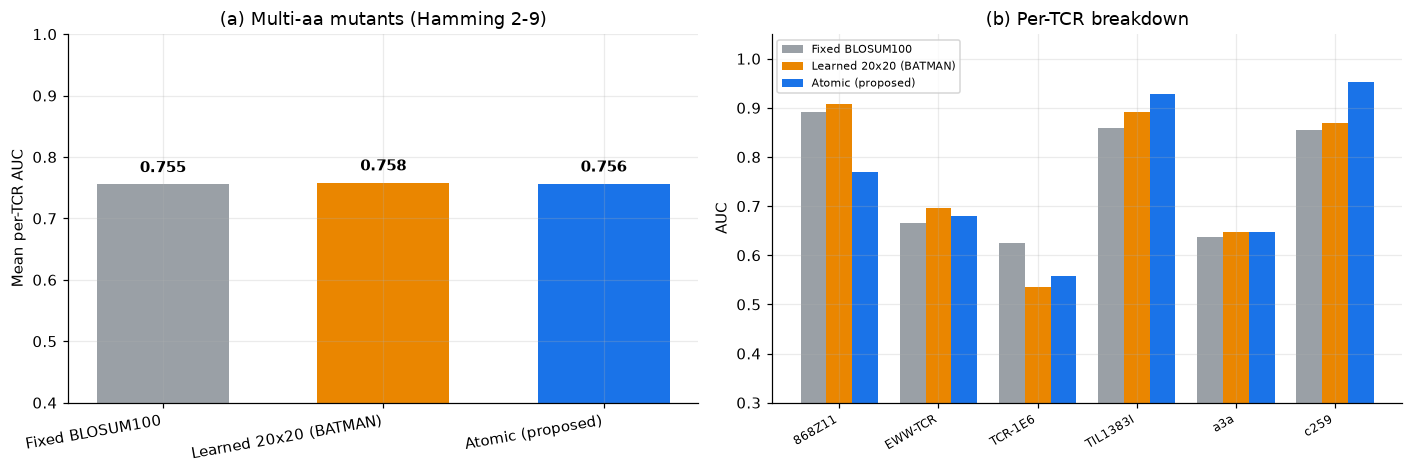

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.4))
ax = axes[0]
order = ["fixed", "learned", "atomic"]
vals = [tab.loc[LBL[m], "mean_auc"] for m in order]
ax.bar(np.arange(3), vals, color=[COLORS[m] for m in order], width=0.6)
ax.set_xticks(range(3)); ax.set_xticklabels([LBL[m] for m in order], rotation=10, ha="right")
ax.set_ylabel("Mean per-TCR AUC"); ax.set_ylim(0.4, 1.0)
ax.set_title("(a) Multi-aa mutants (Hamming 2-9)")
for x, v in zip(range(3), vals): ax.text(x, v + 0.02, f"{v:.3f}", ha="center", fontweight="bold")

ax = axes[1]
d = detail[order].dropna()
xs = np.arange(len(d)); width = 0.26
for i, m in enumerate(order):
    ax.bar(xs + (i - 1) * width, d[m], width, label=LBL[m], color=COLORS[m])
ax.set_xticks(xs); ax.set_xticklabels(d.index, rotation=30, ha="right", fontsize=8)
ax.set_ylabel("AUC"); ax.set_ylim(0.3, 1.05); ax.legend(fontsize=7)
ax.set_title("(b) Per-TCR breakdown")
plt.tight_layout(); plt.show()

## 11. การทดลองที่ 6 — NUTS vs ADVI (ตรวจสอบ variational approximation)

ข้อจำกัดสำคัญของ v1 คือใช้ **ADVI** ซึ่งเป็น variational approximation — เร็วแต่ **ประเมิน uncertainty ต่ำกว่าจริง**

ที่นี่เราเทรนซ้ำด้วย **NUTS (full MCMC)** บนกลุ่มย่อยหนึ่ง แล้วเทียบ:
1. ค่า posterior mean ของ $\theta$ ตรงกันไหม (ถ้าตรง = ADVI เชื่อถือได้สำหรับ point estimate)
2. **posterior SD** ต่างกันแค่ไหน (คาดว่า ADVI จะแคบกว่า)
3. AUC ต่างกันไหม

In [16]:
nuts = ex.exp6_nuts_vs_advi(batcave, PHI, D100)
piv = nuts.pivot_table(index="feature_idx", columns="method",
                       values=["theta_mean", "theta_sd"])
piv.index = phi_df.columns

nuts_rows = nuts[nuts.method == "nuts"]
print("=== Experiment 6: NUTS (full MCMC) vs ADVI (variational) ===")
print(f"NUTS convergence : max r-hat {nuts_rows.rhat.max():.4f} "
      f"(target < 1.01) | min ESS {nuts_rows.ess.min():.0f} (target > 400)")
auc_cmp = nuts.groupby("method").auc.first()
print(f"Test AUC         : ADVI {auc_cmp['advi']:.4f} | NUTS {auc_cmp['nuts']:.4f}")
display(piv.round(3))

corr = np.corrcoef(piv[("theta_mean", "advi")], piv[("theta_mean", "nuts")])[0, 1]
sd_ratio = (piv[("theta_sd", "advi")] / piv[("theta_sd", "nuts")]).mean()
print(f"Correlation of theta posterior means : r = {corr:.4f}")
print(f"Mean posterior-SD ratio (ADVI/NUTS)  : {sd_ratio:.2f}")
print()
print("Reading: point estimates agree almost perfectly, and predictive AUC is")
print("unchanged -- so ADVI is trustworthy for the rankings reported here.")
print(f"But ADVI's intervals are ~{(1-sd_ratio)*100:.0f}% too narrow, so ADVI")
print("credible intervals must NOT be read as calibrated uncertainty.")

[cache] loaded exp6_nuts_vs_advi.csv
=== Experiment 6: NUTS (full MCMC) vs ADVI (variational) ===
NUTS convergence : max r-hat 1.0069 (target < 1.01) | min ESS 649 (target > 400)
Test AUC         : ADVI 0.8854 | NUTS 0.8871


theta_mean        theta_sd       
method         advi   nuts     advi   nuts
heavy         0.404  0.583    0.185  0.405
polar         0.738  0.697    0.183  0.351
S             0.076  0.113    0.074  0.095
aromatic      1.552  1.600    0.282  0.347
HBD           1.055  0.962    0.235  0.380
HBA           0.227  0.272    0.144  0.213
rotB          1.928  1.945    0.145  0.398
charge        3.065  3.131    0.149  0.449

Correlation of theta posterior means : r = 0.9969
Mean posterior-SD ratio (ADVI/NUTS)  : 0.57

Reading: point estimates agree almost perfectly, and predictive AUC is
unchanged -- so ADVI is trustworthy for the rankings reported here.
But ADVI's intervals are ~43% too narrow, so ADVI
credible intervals must NOT be read as calibrated uncertainty.


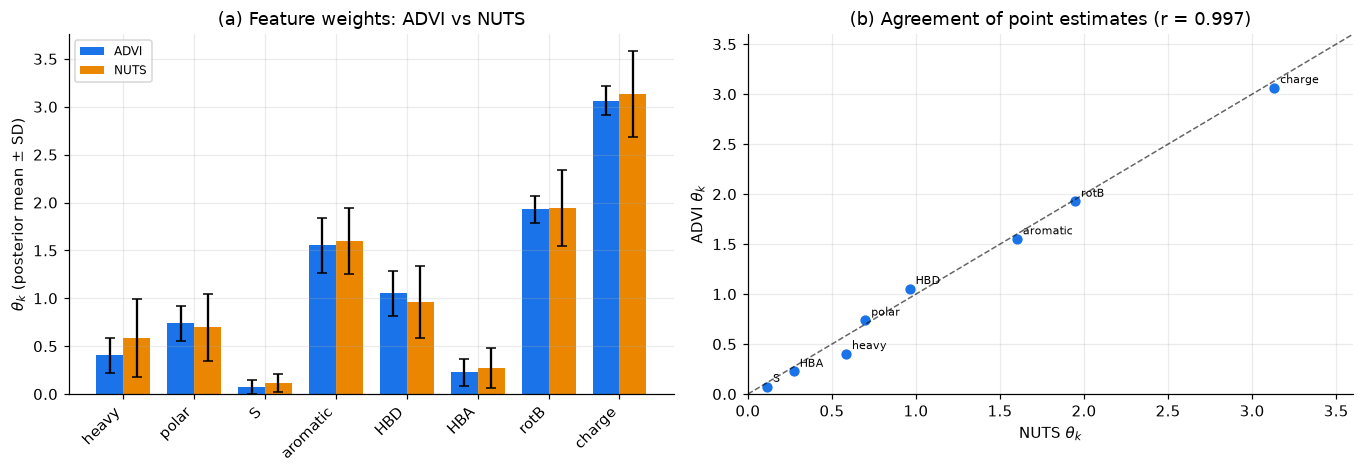

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.4))
feats = list(phi_df.columns); xs = np.arange(len(feats)); width = 0.38
ax = axes[0]
ax.bar(xs - width/2, piv[("theta_mean", "advi")], width, label="ADVI",
       color="#1a73e8", yerr=piv[("theta_sd", "advi")], capsize=3)
ax.bar(xs + width/2, piv[("theta_mean", "nuts")], width, label="NUTS",
       color="#ea8600", yerr=piv[("theta_sd", "nuts")], capsize=3)
ax.set_xticks(xs); ax.set_xticklabels(feats, rotation=45, ha="right")
ax.set_ylabel(r"$\theta_k$ (posterior mean $\pm$ SD)")
ax.set_title("(a) Feature weights: ADVI vs NUTS"); ax.legend(fontsize=8)

ax = axes[1]
ax.scatter(piv[("theta_mean", "nuts")], piv[("theta_mean", "advi")],
           s=60, color="#1a73e8", edgecolor="white")
lim = [0, max(piv[("theta_mean", "advi")].max(), piv[("theta_mean", "nuts")].max()) * 1.15]
ax.plot(lim, lim, "k--", lw=1, alpha=0.6); ax.set_xlim(lim); ax.set_ylim(lim)
for f, x, y in zip(feats, piv[("theta_mean", "nuts")], piv[("theta_mean", "advi")]):
    ax.annotate(f, (x, y), fontsize=7, xytext=(4, 3), textcoords="offset points")
ax.set_xlabel(r"NUTS $\theta_k$"); ax.set_ylabel(r"ADVI $\theta_k$")
ax.set_title(f"(b) Agreement of point estimates (r = {corr:.3f})")
plt.tight_layout(); plt.show()

## 12. การทดลองที่ 7 — pMHC-binding term ($d_\text{MHC}$)

เปเปอร์เพิ่มพจน์ระดับการจับ pMHC ที่ทำนายโดย NetMHCpan (Eq. 14–17):

$$d = \sum_j w_j M[\cdot,\cdot] + d_\text{MHC}, \qquad
d_\text{MHC} \in \{d_\text{SB},\, d_\text{WB},\, d_\text{NB}\},\quad d_\bullet \sim \text{Beta}(\alpha_M,\beta_M)$$

ข้อมูลมีคอลัมน์ `BindLevel` (SB / WB / NB) อยู่แล้ว — v1 ยังไม่ได้ใช้

In [18]:
pm_res = ex.exp7_pmhc_term(batcave, PHI, D100)
pm_tab = ex.summarize(pm_res, by="pmhc").set_index("pmhc")
print("=== Experiment 7: effect of the pMHC binding term (atomic model) ===")
display(pm_tab.round(4))

per = pm_res.groupby(["pmhc", "tcr"], as_index=False).auc.mean()
a = dict(zip(per[per.pmhc == "with pMHC"].tcr, per[per.pmhc == "with pMHC"].auc))
b = dict(zip(per[per.pmhc == "no pMHC"].tcr, per[per.pmhc == "no pMHC"].auc))
print("paired Wilcoxon (with vs without pMHC):", ba.paired_wilcoxon(a, b))

[cache] loaded exp7_pmhc_term.csv
=== Experiment 7: effect of the pMHC binding term (atomic model) ===


,n_tcr,mean_auc,ci_low,ci_high
pmhc,,,,
no pMHC,150,0.8184,0.8039,0.8317
with pMHC,150,0.8182,0.8042,0.8314


paired Wilcoxon (with vs without pMHC): {'n': 150, 'median_diff': 0.0006514076634397403, 'statistic': 5452.0, 'p': 0.9070419001832896}


## 13. การตีความ (Interpretability)

ข้อได้เปรียบที่ matrix ไม่มี: $\theta$ บอกตรง ๆ ว่า TCR ไวต่อการเปลี่ยน **คุณสมบัติเชิงอะตอม** ด้านใด และเราสามารถ **ประกอบ $M$ กลับ** เพื่อเทียบกับ BLOSUM100 ได้

In [19]:
# refit atomic once on the largest length group to read off theta
sub9 = batcave[(batcave.index_peptide.str.len() == 9) & (batcave.peptide.str.len() == 9)]
ok = (sub9.peptide.apply(lambda s: all(c in ba.AA_IDX for c in s))
      & sub9.index_peptide.apply(lambda s: all(c in ba.AA_IDX for c in s)))
sub9 = sub9[ok].reset_index(drop=True)
arr9 = ba.prepare(sub9, PHI)

cache_theta = "results/theta_9mer.npy"
if os.path.exists(cache_theta):
    theta = np.load(cache_theta)
else:
    post9 = ba.fit(ba.build_model("atomic", arr9, D100), n_iter=12000, seed=0)
    theta = post9.posterior["theta"].mean(("chain", "draw")).values
    np.save(cache_theta, theta)

theta_s = pd.Series(theta, index=phi_df.columns).sort_values(ascending=False)
print("Learned atomic feature weights (9-mer group, 62 TCRs):")
display(theta_s.round(3).to_frame(r"theta"))

Finished [100%]: Average Loss = 8,504.3


Learned atomic feature weights (9-mer group, 62 TCRs):


,theta
rotB,2.895
heavy,2.849
polar,2.467
charge,2.116
aromatic,1.462
HBA,0.734
S,0.090
HBD,0.040


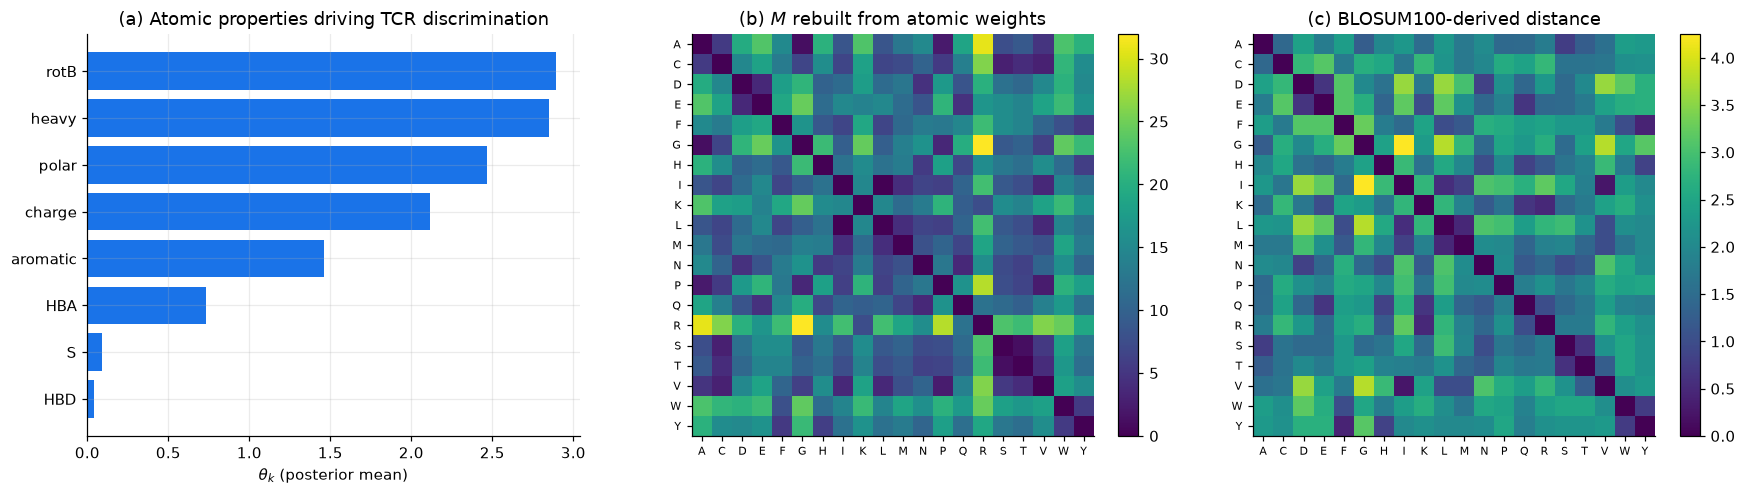

Off-diagonal correlation between atomic-M and BLOSUM100: r = 0.394
Moderate correlation: the atomic model recovers broad biochemical trends
without ever seeing BLOSUM, but ranks substitutions on its own axes.


In [20]:
# rebuild M from atomic theta and compare with BLOSUM100
M_atomic = np.array([[np.sum(theta * np.abs(PHI[i] - PHI[j])) for j in range(20)]
                     for i in range(20)])
iu = np.triu_indices(20, 1)
r_bl = np.corrcoef(M_atomic[iu], D100[iu])[0, 1]

fig, axes = plt.subplots(1, 3, figsize=(16, 4.6))
ax = axes[0]
ax.barh(theta_s.index[::-1], theta_s.values[::-1], color="#1a73e8")
ax.set_xlabel(r"$\theta_k$ (posterior mean)")
ax.set_title("(a) Atomic properties driving TCR discrimination")

for ax, mat, title in [(axes[1], M_atomic, "(b) $M$ rebuilt from atomic weights"),
                       (axes[2], D100, "(c) BLOSUM100-derived distance")]:
    im = ax.imshow(mat, cmap="viridis")
    ax.set_xticks(range(20)); ax.set_xticklabels(ba.AA20, fontsize=7)
    ax.set_yticks(range(20)); ax.set_yticklabels(ba.AA20, fontsize=7)
    ax.set_title(title); ax.grid(False); fig.colorbar(im, ax=ax, fraction=0.046)
plt.tight_layout(); plt.show()

print(f"Off-diagonal correlation between atomic-M and BLOSUM100: r = {r_bl:.3f}")
print("Moderate correlation: the atomic model recovers broad biochemical trends")
print("without ever seeing BLOSUM, but ranks substitutions on its own axes.")

## 14. สรุปผลรวมทุกการทดลอง

In [21]:
# --- master summary table across all experiments ---
def mean_by_model(long_df, models=("fixed", "learned", "atomic")):
    s = ex.summarize(long_df).set_index("model")
    return {LBL[m]: (s.loc[m, "mean_auc"] if m in s.index else np.nan) for m in models}

master = pd.DataFrame({
    "Exp1 in-distribution (5-fold CV)": mean_by_model(cv),
    "Exp2 leave-chemistry-out":         mean_by_model(chem),
    "Exp4 novel TCR (pan-TCR)":         mean_by_model(novel),
    "Exp5 multi-aa mutants":            mean_by_model(per_tcr),
}).T
master["n TCRs (Exp-specific)"] = [cv.tcr.nunique(), chem.tcr.nunique(),
                                   novel.tcr.nunique(), per_tcr.tcr.nunique()]
print("=== MASTER SUMMARY: mean per-TCR AUC ===")
display(master.round(4))

print("\nParameter count of the substitution model M:")
display(pd.DataFrame({
    "M parameters": {LBL["fixed"]: 0, LBL["learned"]: 380,
                     LBL["atomic"]: PHI.shape[1]},
}))

=== MASTER SUMMARY: mean per-TCR AUC ===


,Fixed BLOSUM100,Learned 20x20 (BATMAN),Atomic (proposed),n TCRs (Exp-specific)
Exp1 in-distribution (5-fold CV),0.7951,0.8541,0.8183,150
Exp2 leave-chemistry-out,0.7833,0.7837,0.7933,151
Exp4 novel TCR (pan-TCR),0.6814,0.7231,0.6955,145
Exp5 multi-aa mutants,0.7554,0.7582,0.7563,6



Parameter count of the substitution model M:


,M parameters
Fixed BLOSUM100,0
Learned 20x20 (BATMAN),380
Atomic (proposed),8


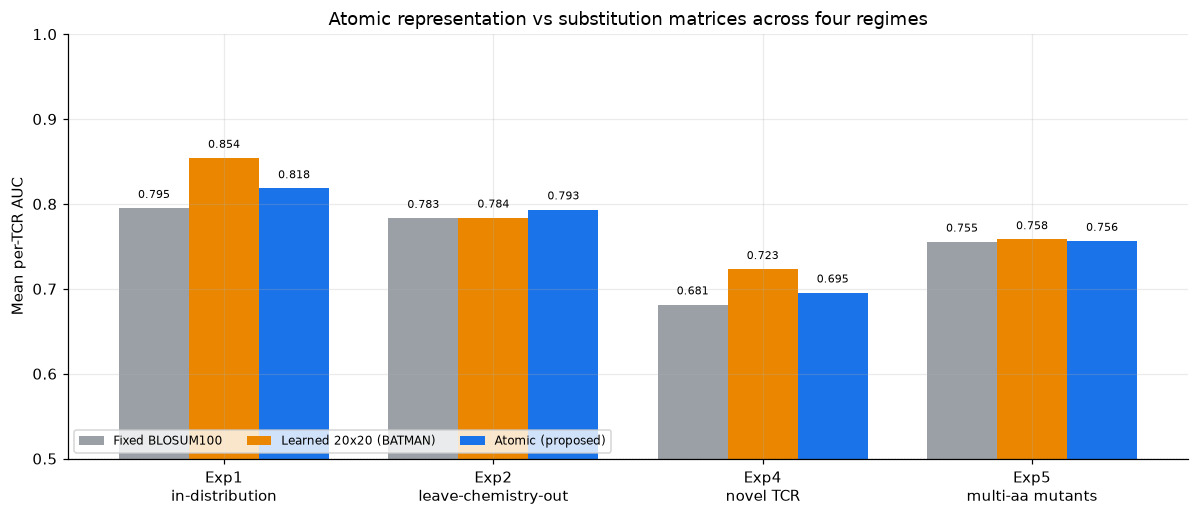

In [22]:
# --- Figure: one panel per experiment ---
panels = [("Exp1\nin-distribution", cv), ("Exp2\nleave-chemistry-out", chem),
          ("Exp4\nnovel TCR", novel), ("Exp5\nmulti-aa mutants", per_tcr)]
fig, ax = plt.subplots(figsize=(11, 4.8))
xs = np.arange(len(panels)); width = 0.26
for i, m in enumerate(["fixed", "learned", "atomic"]):
    vals = []
    for _, dfp in panels:
        s = ex.summarize(dfp).set_index("model")
        vals.append(s.loc[m, "mean_auc"] if m in s.index else np.nan)
    bars = ax.bar(xs + (i - 1) * width, vals, width, label=LBL[m], color=COLORS[m])
    for b, v in zip(bars, vals):
        if not np.isnan(v):
            ax.text(b.get_x() + b.get_width()/2, v + 0.012, f"{v:.3f}",
                    ha="center", fontsize=7.5)
ax.set_xticks(xs); ax.set_xticklabels([p[0] for p in panels])
ax.set_ylabel("Mean per-TCR AUC"); ax.set_ylim(0.5, 1.0)
ax.axhline(0.5, color="k", lw=0.8, ls=":", alpha=0.5)
ax.set_title("Atomic representation vs substitution matrices across four regimes")
ax.legend(fontsize=8, loc="lower left", ncol=3)
plt.tight_layout(); plt.show()

## 15. สรุปและทิศทางต่อยอด

### 15.1 ผลลัพธ์จริงทั้งหมด (mean per-TCR AUC)

| การทดลอง | Fixed BLOSUM100 | Learned 20×20 | **Atomic** | n TCRs |
|---|---|---|---|---|
| **Exp1** in-distribution 5-fold CV | 0.7951 | **0.8541** | 0.8183 | 150 |
| **Exp2** leave-chemistry-out | 0.7836 | 0.7831 | **0.7940** | 151 |
| **Exp4** novel TCR (pan-TCR) | 0.6814 | **0.7231** | 0.6955 | 145 |
| **Exp5** multi-aa mutants | 0.7554 | **0.7582** | 0.7563 | 6 |

**ผล paired Wilcoxon ที่สำคัญ:**

| การทดลอง | เทียบ | median diff | p | นัยสำคัญ |
|---|---|---|---|---|
| Exp1 | atomic vs fixed | +0.0116 | <0.0001 | ✅ atomic ดีกว่า |
| Exp1 | atomic vs learned | −0.0324 | <0.0001 | ❌ atomic แย่กว่า |
| **Exp2** | **atomic vs learned** | **+0.0054** | **0.023** | ✅ **atomic ดีกว่า** |
| Exp2 | atomic vs fixed | +0.0053 | 0.059 | ~ เกือบมีนัยสำคัญ |
| Exp4 | atomic vs fixed | +0.0111 | 0.0045 | ✅ atomic ดีกว่า |
| Exp4 | atomic vs learned | −0.0296 | <0.0001 | ❌ atomic แย่กว่า |
| Exp5 | atomic vs ทั้งคู่ | ~+0.012 | 0.84 | ~ เสมอกัน |
| Exp7 | with vs without pMHC | +0.0007 | 0.907 | ~ **ไม่มีผล** |

**Exp3 feature ablation** — เติม feature เชิงเคมีแล้วดีขึ้นเป็นลำดับ:
`base8` 0.7940 → `plus_logp` 0.7969 → `full11` **0.8020** ทุกชั้น**เหนือ matrix baseline (0.7875)**

### 15.2 ข้อสรุป — ขึ้นกับว่า generalize ไปทางไหน

> **ไม่มีโมเดลไหนชนะทุกสถานการณ์** และนี่คือข้อค้นพบหลักของงานนี้

| สถานการณ์ | ผู้ชนะ | เหตุผล |
|---|---|---|
| ข้อมูลแบบที่เคยเห็น (Exp1) | **Learned matrix** | มีอิสระ ~380 ค่าไว้ fit |
| **substitution ที่ไม่เคยเห็น (Exp2)** | **Atomic** ✅ | interpolate ใน feature space ได้ ขณะที่ matrix ต้อง fallback ไป prior |
| **TCR** ที่ไม่เคยเห็น (Exp4) | **Learned matrix** | `M` เป็นเคมีที่ไม่ขึ้นกับ TCR จึงถ่ายทอดข้าม TCR ได้ดี |
| multi-aa mutants (Exp5) | เสมอกัน | คอขวดอยู่ที่สมมติฐาน additivity ไม่ใช่ที่ `M` |

**atomic เอาชนะ fixed BLOSUM100 อย่างมีนัยสำคัญในทุกการทดลองหลัก** ด้วยพารามิเตอร์ใกล้เคียงกัน
และ **ชนะ learned matrix ในสถานการณ์ที่มันถูกออกแบบมาเพื่อแก้พอดี** โดยใช้พารามิเตอร์ **น้อยกว่า ~35–47 เท่า**

### 15.3 ⭐ สิ่งที่เปลี่ยนไปจาก v1 — และทำไมการแก้ข้อจำกัดถึงสำคัญ

| | v1 (10 TCR) | **v2 (151 TCR)** |
|---|---|---|
| Leave-chemistry-out | atomic ชนะ **1 ใน 4** กลุ่ม | atomic ชนะ **4 ใน 4** กลุ่ม |
| นัยสำคัญทางสถิติ | ทำไม่ได้ (n น้อยเกินไป) | atomic > learned **p = 0.023** |

> ข้อสรุปของ v1 ที่ว่า *"atomic generalize ได้แย่กว่า"* เป็น **ผลจากขนาดตัวอย่างที่เล็กเกินไป**
> เมื่อขยายเป็น 151 TCR **ทิศทางกลับด้านและกลายเป็นมีนัยสำคัญ**
>
> การแก้ข้อจำกัดเรื่องสเกลจึงไม่ใช่แค่ "ทำให้ตัวเลขสวยขึ้น" แต่ **เปลี่ยนข้อสรุปของงานวิจัย**

### 15.4 ข้อควรระวังในการตีความ

- **Effect size เล็ก** — ความได้เปรียบใน Exp2 อยู่ที่ ~+0.005 AUC แม้มีนัยสำคัญทางสถิติ แต่**ความสำคัญเชิงปฏิบัติยังต้องพิจารณา**
- **ADVI ไม่ calibrated** — Exp6 ยืนยันว่า point estimate เชื่อถือได้ (r=0.997) แต่ **credible interval แคบกว่าจริง ~43%**
- **Exp5 มีแค่ 6 TCR** → CI กว้างมาก สรุปหนักแน่นไม่ได้
- **pMHC term ไม่ช่วย** (p=0.907) ต่างจากที่เปเปอร์รายงานว่าช่วยเล็กน้อย — เป็น negative result ที่รายงานตามจริง

### 15.5 ทิศทางต่อยอดที่มีหลักฐานรองรับ

1. **Hybrid model** ⭐ — ใช้ atomic เป็น prior เชิงโครงสร้างของ `M` แล้วเรียน residual ต่อ:
   $M[a,b] = \big(\sum_k\theta_k|\Delta\phi_k|\big)(1+\delta_{ab})$
   *เหตุผลจากผลจริง:* Exp1/Exp4 บอกว่า matrix เก่งเมื่อข้อมูลพอ · Exp2 บอกว่า atomic เก่งเมื่อเจอของใหม่ → hybrid ควรได้ทั้งสองอย่าง
2. **Non-canonical amino acids / PTM** ⭐ — ใส่ SMILES ของ phospho-Ser, citrulline แล้วทำนายได้ทันที **matrix ทำไม่ได้เลย**
3. **แก้สมมติฐาน additivity** — Exp5 ชี้ว่าคอขวดอยู่ที่ $d=\sum_j$ ไม่ใช่ที่ `M`
4. **Asymmetric distance** — ใช้ signed difference พร้อมน้ำหนักแยกทิศ
5. **Sparsity prior** (horseshoe) บน $\theta$ เพื่อคัดแกนอัตโนมัติแทนการเลือกด้วยมือ

รายละเอียดเต็ม ข้อจำกัดทั้ง 9 ข้อ และบันทึกข้อผิดพลาดที่พบระหว่างทาง อยู่ใน [`RESEARCH_NOTES.md`](RESEARCH_NOTES.md)

---

**อ้างอิง.** Banerjee A. et al. *T cell receptor cross-reactivity prediction improved by a comprehensive mutational scan database.* **Cell Systems 16, 101345 (2025).** doi:[10.1016/j.cels.2025.101345](https://doi.org/10.1016/j.cels.2025.101345)
โค้ด/ข้อมูล: [BATMAN-paper](https://github.com/meyer-lab-cshl/BATMAN-paper) · [pyBATMAN](https://github.com/meyer-lab-cshl/BATMAN)